# Loan Default Risk & Pricing — LendingClub 2007–2018

| Part | Sections | Owner | Viva focus |
|---|---|---|---|
| **A** | 1–8 | Student 1 | Data, leakage policy, EDA, features, baselines |
| **B** | 9–12 | Student 2 | Bias–variance, Random Forest, XGBoost tuning, feature selection |
| **C** | 13–17 | Student 3 | Model comparison, calibration, evaluation, pricing, deployment |

In [1]:
import os, gc, json, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, validation_curve
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    precision_recall_curve, RocCurveDisplay, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
import joblib

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
N_ITER  = int(os.environ.get('LC_NITER', 18))
N_BOOT  = int(os.environ.get('LC_NBOOT', 500))
plt.rcParams['figure.dpi'] = 110

## 1. Problem

A lender commits money before knowing whether it comes back. We predict the **probability of default** using only what is known at application time.

Two errors, unequal costs: **approving a defaulter** loses most of the principal; **rejecting a good borrower** loses only the profit on that loan. We assume the first mistake costs **5×** more — that asymmetry drives every downstream decision on threshold and pricing.

Live app: **http://eab-credit.preview.james-benjamin.com/**

## 2. Data & Leakage Policy

| Group | Examples | Role |
|---|---|---|
| Application-time | loan amount, income, DTI, FICO, credit bureau counts | **Model inputs** |
| LC's own pricing | `int_rate`, `grade`, `sub_grade` | **Benchmark only** — never a model input |
| Outcome | `loan_status` | Builds the target |
| Post-origination | payments received, recoveries | **LGD measurement only** |

Using LC's pricing as a model input would be circular: we would be predicting risk from risk.

In [2]:
import kagglehub
DATA_DIR = kagglehub.dataset_download('wordsforthewise/lending-club')
DATA_PATH = str(list(pathlib.Path(DATA_DIR).rglob('accepted_2007_to_2018Q4.csv*'))[0])

ALL_COLS = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()

NUMERIC_CANDS = [
    'loan_amnt','annual_inc','dti','delinq_2yrs','inq_last_6mths','open_acc','pub_rec',
    'revol_bal','revol_util','total_acc','collections_12_mths_ex_med','acc_now_delinq',
    'tot_coll_amt','tot_cur_bal','total_rev_hi_lim','acc_open_past_24mths','avg_cur_bal',
    'bc_open_to_buy','bc_util','chargeoff_within_12_mths','delinq_amnt',
    'mo_sin_old_rev_tl_op','mo_sin_rcnt_rev_tl_op','mo_sin_rcnt_tl','mort_acc',
    'mths_since_recent_inq','num_accts_ever_120_pd','num_actv_bc_tl','num_actv_rev_tl',
    'num_bc_sats','num_bc_tl','num_il_tl','num_op_rev_tl','num_rev_accts',
    'num_rev_tl_bal_gt_0','num_sats','num_tl_120dpd_2m','num_tl_30dpd',
    'num_tl_90g_dpd_24m','pct_tl_nvr_dlq','percent_bc_gt_75','pub_rec_bankruptcies',
    'tax_liens','tot_hi_cred_lim','total_bal_ex_mort','total_bc_limit',
    'total_il_high_credit_limit','fico_range_low','fico_range_high',
]
CAT_CANDS   = ['term','emp_length','home_ownership','verification_status','purpose','application_type']
DATE_COLS   = ['issue_d','earliest_cr_line']
BENCHMARK   = ['int_rate','grade','sub_grade']
OUTCOME     = ['funded_amnt','total_rec_prncp','recoveries']

keep = lambda cols: [c for c in cols if c in ALL_COLS]
USECOLS = sorted(set(
    keep(NUMERIC_CANDS) + keep(CAT_CANDS) + keep(DATE_COLS)
    + ['loan_status'] + keep(BENCHMARK) + keep(OUTCOME)
))

parts = []
for i, chunk in enumerate(pd.read_csv(DATA_PATH, usecols=USECOLS, chunksize=200_000, low_memory=False)):
    chunk = chunk[chunk['loan_status'].isin(['Fully Paid','Charged Off'])]
    if len(chunk):
        parts.append(chunk.sample(frac=0.08, random_state=RANDOM_STATE + i))
df = pd.concat(parts, ignore_index=True)
if len(df) > 150_000:
    df = df.sample(150_000, random_state=RANDOM_STATE)
del parts; gc.collect()

print(f'Sample: {df.shape[0]:,} rows, {df.shape[1]} columns')
print(f'Default rate: {(df["loan_status"]=="Charged Off").mean():.1%}')

Sample: 107,625 rows, 64 columns
Default rate: 20.0%


## 3. Cleaning & Target

Rules use fixed business limits, not data percentiles — no information leaks from test into train.

In [3]:
DF = df.copy()
DF['default'] = (DF['loan_status'] == 'Charged Off').astype(int)

# Type fixes
for c in keep(DATE_COLS):
    DF[c] = pd.to_datetime(DF[c], format='%b-%Y', errors='coerce')
if 'revol_util' in DF and DF['revol_util'].dtype == object:
    DF['revol_util'] = pd.to_numeric(DF['revol_util'].str.rstrip('%'), errors='coerce')
DF['term'] = DF['term'].astype(str).str.strip()
DF['fico_avg'] = DF[['fico_range_low','fico_range_high']].mean(axis=1)

# Business caps
before = len(DF)
DF = DF[DF['annual_inc'] > 0].copy()
DF['dti']       = DF['dti'].clip(0, 100)
DF['revol_util'] = DF['revol_util'].clip(0, 150)
DF['annual_inc'] = DF['annual_inc'].clip(upper=1_000_000)
DF = DF.replace([np.inf, -np.inf], np.nan).dropna(subset=['issue_d'])
DF = DF.sort_values('issue_d').reset_index(drop=True)

print(f'Removed {before - len(DF):,} rows | {len(DF):,} remain | default rate {DF["default"].mean():.1%}')

Removed 31 rows | 107,594 remain | default rate 20.0%


## 4. Exploratory Data Analysis

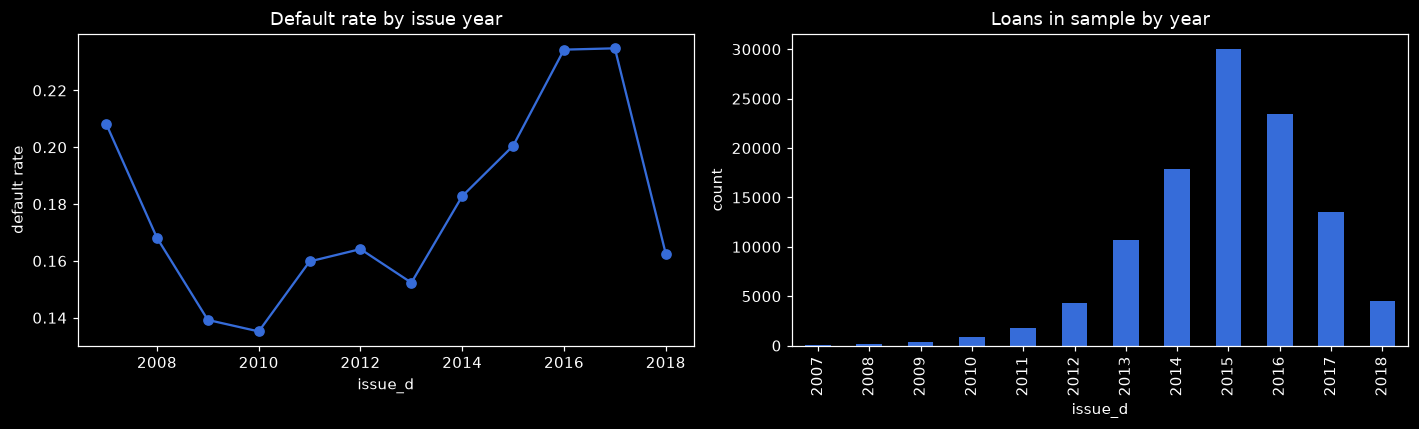

In [4]:
year = DF['issue_d'].dt.year
by_year = DF.groupby(year)['default'].agg(loans='size', default_rate='mean')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_year['default_rate'].plot(marker='o', ax=axes[0], title='Default rate by issue year', ylabel='default rate')
by_year['loans'].plot(kind='bar', ax=axes[1], title='Loans in sample by year', ylabel='count')
plt.tight_layout(); plt.show()

**Finding:** Default rate shifts with time — a random train/test split would mix future signal into training. We use a time-based split.

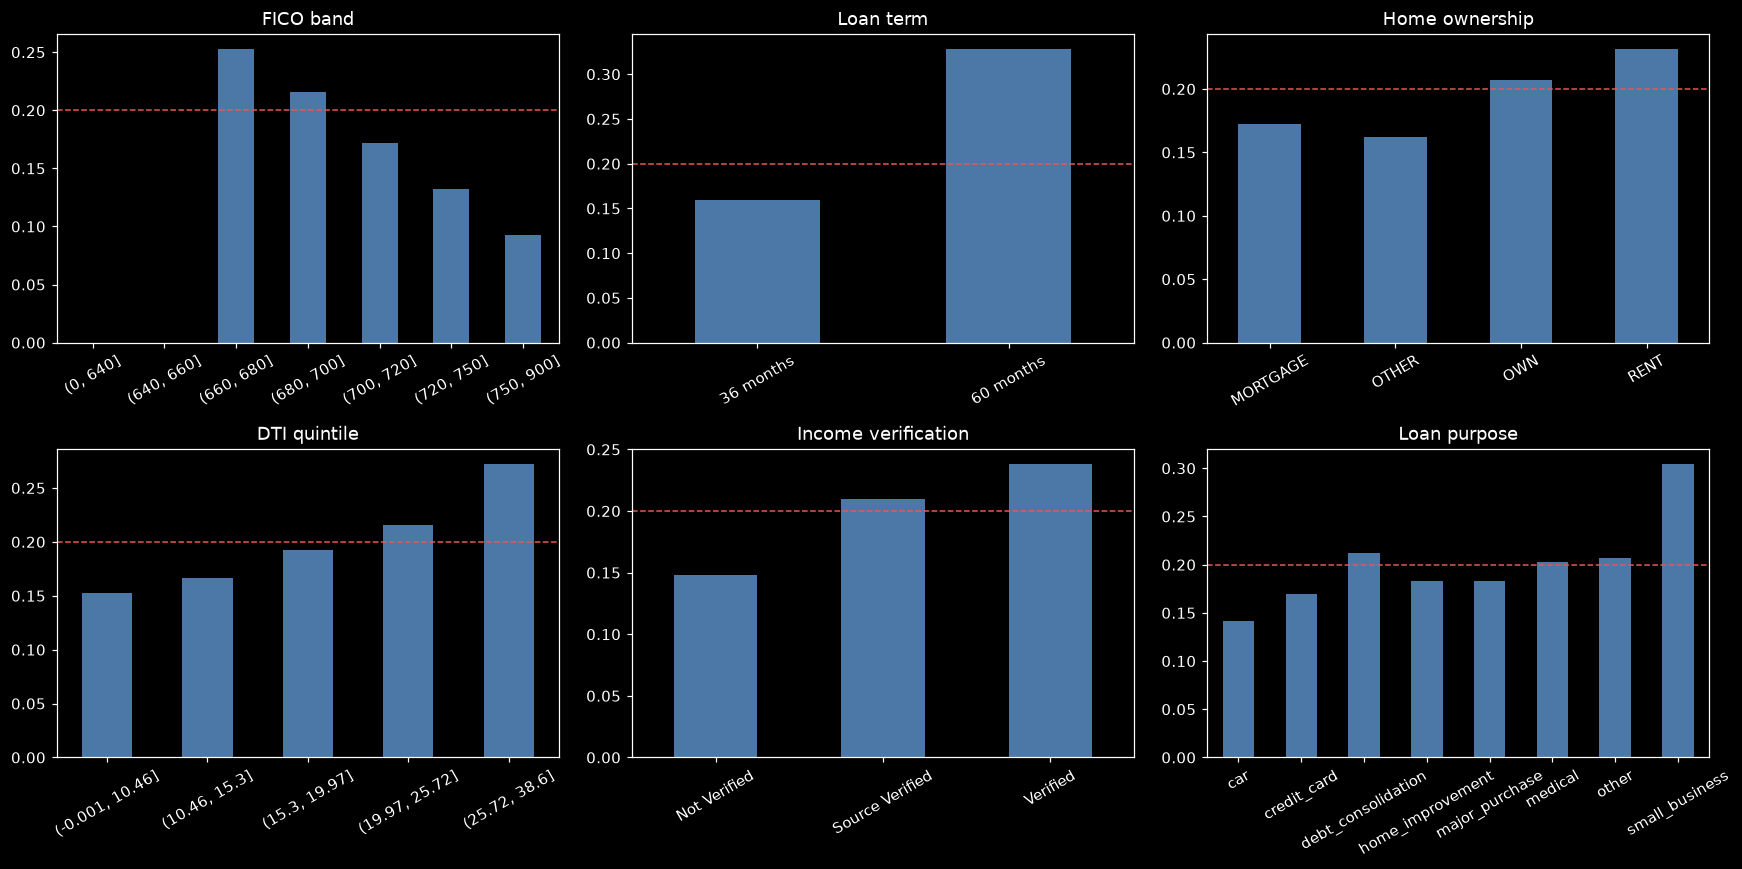

In [5]:
def rate_bar(series, ax, title):
    rate = DF.groupby(series, observed=False)['default'].mean()
    rate.plot(kind='bar', ax=ax, color='#4C78A8')
    ax.axhline(DF['default'].mean(), color='#E45756', ls='--', lw=1)
    ax.set_title(title); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
rate_bar(pd.cut(DF['fico_avg'], [0,640,660,680,700,720,750,900]), ax[0,0], 'FICO band')
rate_bar(DF['term'], ax[0,1], 'Loan term')
rate_bar(DF['home_ownership'].where(DF['home_ownership'].isin(['MORTGAGE','RENT','OWN']),'OTHER'), ax[0,2], 'Home ownership')
dti_c = DF['dti'].clip(upper=DF['dti'].quantile(0.99))
rate_bar(pd.qcut(dti_c, 5, duplicates='drop'), ax[1,0], 'DTI quintile')
rate_bar(DF['verification_status'], ax[1,1], 'Income verification')
top_p = DF['purpose'].value_counts().head(8).index
rate_bar(DF['purpose'].where(DF['purpose'].isin(top_p), 'other'), ax[1,2], 'Loan purpose')
plt.tight_layout(); plt.show()

**Findings:** Higher FICO → lower default (strongest raw signal). 60-month loans default at roughly twice the rate of 36-month. Verified income often shows *higher* default — lenders verify applicants they already find suspicious.

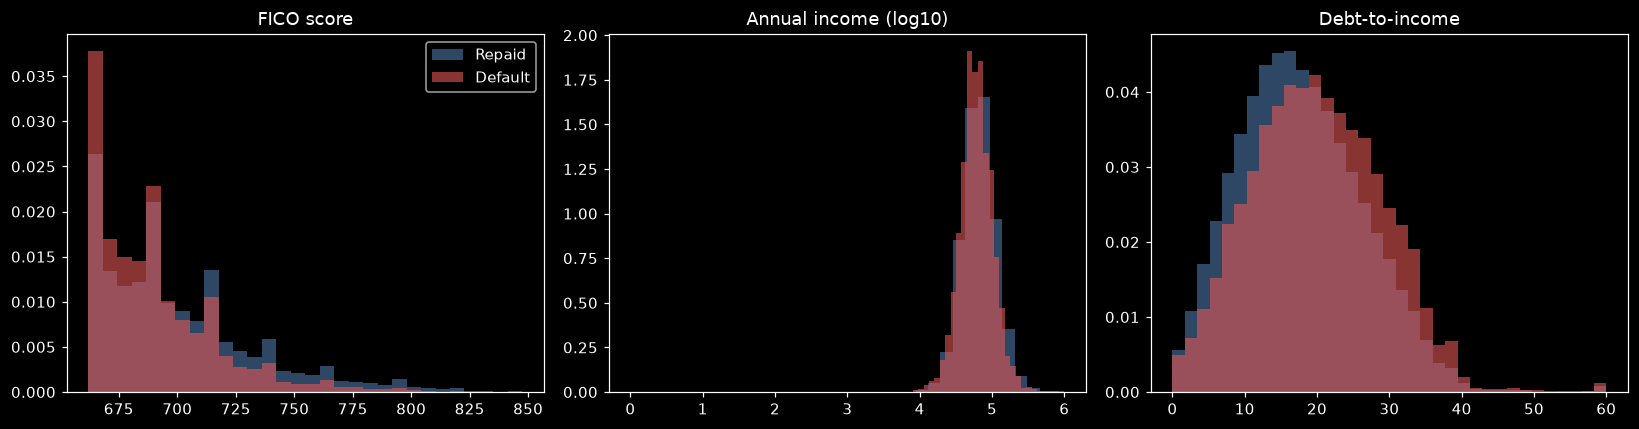

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for label, colour, name in [(0,'#4C78A8','Repaid'), (1,'#E45756','Default')]:
    d = DF[DF['default'] == label]
    ax[0].hist(d['fico_avg'],            bins=30, alpha=0.6, density=True, color=colour, label=name)
    ax[1].hist(np.log10(d['annual_inc']),bins=35, alpha=0.6, density=True, color=colour, label=name)
    ax[2].hist(d['dti'].clip(0,60),      bins=35, alpha=0.6, density=True, color=colour, label=name)
ax[0].set_title('FICO score'); ax[1].set_title('Annual income (log10)'); ax[2].set_title('Debt-to-income')
ax[0].legend(); plt.tight_layout(); plt.show()

**Finding:** Defaulters skew lower FICO and higher DTI, but the distributions overlap heavily — no single variable cleanly separates the classes.

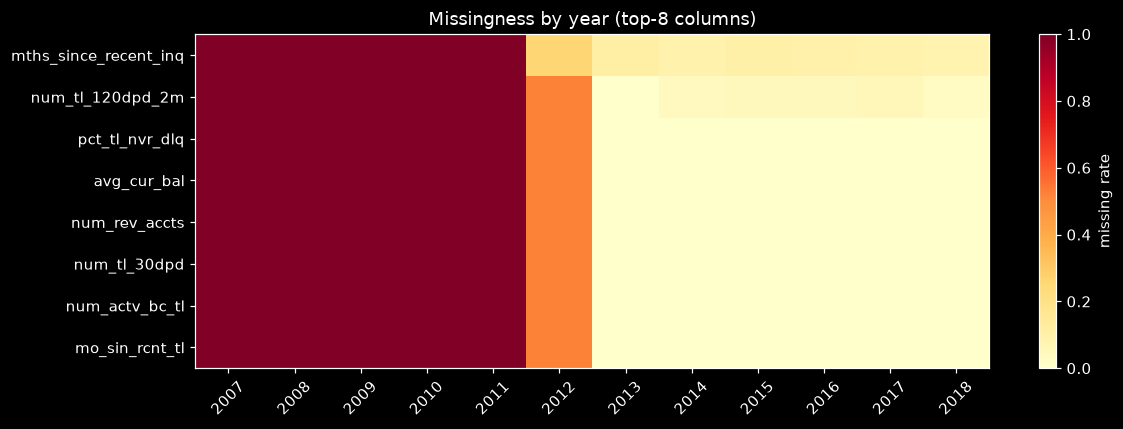

In [7]:
miss_by_year = DF.groupby(year)[keep(NUMERIC_CANDS)].apply(lambda g: g.isna().mean())
top_miss = miss_by_year.mean().sort_values(ascending=False).head(8).index.tolist()
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(miss_by_year[top_miss].T, aspect='auto', cmap='YlOrRd', vmin=0, vmax=1)
ax.set_xticks(range(len(miss_by_year))); ax.set_xticklabels(miss_by_year.index, rotation=45)
ax.set_yticks(range(len(top_miss))); ax.set_yticklabels(top_miss)
plt.colorbar(im, ax=ax, label='missing rate'); ax.set_title('Missingness by year (top-8 columns)')
plt.tight_layout(); plt.show()

**Finding:** Several credit-bureau columns were not collected before 2012–2013. Missingness is systematic, not random — we add missing indicators so the model can use this information.

## 5. Feature Engineering

Two ratio features motivated by the EDA. Each must show a monotone relationship with default to earn its place.

In [8]:
DF['loan_to_income']       = DF['loan_amnt'] / DF['annual_inc'].replace(0, np.nan)
DF['credit_history_years'] = ((DF['issue_d'] - DF['earliest_cr_line']).dt.days / 365.25).clip(lower=0)
# fico_avg already created in section 3

for feat in ['loan_to_income','credit_history_years','fico_avg']:
    s = DF[feat].clip(upper=DF[feat].quantile(0.99))
    dr = DF.groupby(pd.qcut(s, 5, duplicates='drop'), observed=False)['default'].mean().round(3)
    print(f'{feat}:\n  {dr.values}  (monotone = justified)\n')

NUMERIC_FEATS = (
    [c for c in keep(NUMERIC_CANDS) if c not in ('fico_range_low','fico_range_high')]
    + ['fico_avg','loan_to_income','credit_history_years']
)
CAT_FEATS   = keep(CAT_CANDS)
FEAT_COLS   = NUMERIC_FEATS + CAT_FEATS

# Leakage guard
forbidden = set(BENCHMARK + OUTCOME + ['loan_status','default','issue_d','earliest_cr_line'])
assert not (set(FEAT_COLS) & forbidden), set(FEAT_COLS) & forbidden
print(f'Feature set: {len(NUMERIC_FEATS)} numeric + {len(CAT_FEATS)} categorical = {len(FEAT_COLS)} total')

loan_to_income:
  [0.134 0.159 0.186 0.231 0.291]  (monotone = justified)

credit_history_years:
  [0.223 0.213 0.195 0.193 0.175]  (monotone = justified)

fico_avg:
  [0.256 0.236 0.21  0.168 0.11 ]  (monotone = justified)

Feature set: 50 numeric + 6 categorical = 56 total
